# IBM · полный clean-прогон · 100 снимков · v2
## Цель
50 Moon + 50 Mars → **100 forwards детектора, 400 ответов Q1–Q4**.
Только исходные изображения, без искажений, depth, обучения или квантования.
Опубликованный NAC Faster R-CNN head → фиксированный перевод рамок в ответы.
FP32, score ≥0.5 и `crater-reference-v1` не менялись после val-пилота.

**Загрузить новый `ibm_full100_v2.zip` в `MyDrive/planetary_benchmark/`.**
Выполнять сверху вниз на GPU T4. На новой VM установить `DOWNLOAD_WEIGHTS=True`.
После успешного smoke включить `RUN_BENCHMARK=True` только в разделе 7.
Старый ZIP пилота сюда не подходит. Текущий notebook обновлён с val14 на full100;
выполненная пилотная версия сохранена локально в архиве подготовки.

### Что уже проверено и что остаётся ограничением
Пилот 14 сцен реально выполнен на T4 в прежнем зафиксированном окружении.
**Этот полный GPU-прогон ещё не выполнен.** Низкая точность пилота не блокирует
исполнение. Разметка остаётся кандидатной и требует независимой проверки;
результаты не становятся финальными научными метриками автоматически.
Исходные val/test сохранены; в 100 входят старые smoke и val-пилот.
Всего 70 исходных групп; три группы встречаются и в source-val, и в source-test.
Эти пересечения отмечаются локально, а не объявляются чистым holdout.
Ни эталоны, ни маски, ни рамки GT в ZIP или вход модели не передаются.
Некоторые исходные `.png` имеют TIFF-содержимое: байты сохранены, формат
определяется декодером, а не расширением. Нормализация и тензоры не меняются.

## Настройка
### 1. Параметры и Drive
Не повторять эту ячейку перед run: она создаёт SESSION_ID.
При resume оставить тот же RUN_ID и ZIP, поставить RESUME=True,
выполнить setup/assets и новый smoke. Старые run IDs пилота не использовать.

In [21]:
from pathlib import Path
import hashlib, json, os, shutil, stat, subprocess, sys, uuid, zipfile
from google.colab import drive
drive.mount('/content/drive')
PERSIST = Path('/content/drive/MyDrive/planetary_benchmark')
BUNDLE_ZIP = PERSIST/'ibm_full100_v2.zip'
WORKSPACE = Path('/content/planetary_ibm_full100_v2')
VENV = Path('/content/venv_ibm_full100_v2')
# На той же VM повторно используем прежний IBM venv; не SpaceLLaVA.
for previous_env in (Path('/content/venv_ibm_val14_v1'), Path('/content/venv_ibm_craters_v1')):
    if (previous_env/'bin/python').is_file():
        VENV = previous_env
        break
PYTHON = str(VENV/'bin/python')
RUN_ID = 'ibm_full100_v2_clean'
SESSION_ID = uuid.uuid4().hex
DOWNLOAD_WEIGHTS = False  # True при первой явной загрузке IBM weights/runtime
RUN_SMOKE = True
RESUME = False
PERSIST.mkdir(parents=True, exist_ok=True)
print('Session:', SESSION_ID, '| local disk GiB:', round(shutil.disk_usage('/content').free/2**30, 1))
subprocess.run(['nvidia-smi'], check=True)

REUSE_OLD_ASSETS = True


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Session: 72871d1a61094934b4813622e463d071 | local disk GiB: 58.7


### 2. Хеши ZIP и распаковка
Старые workspaces и прогоны не перезаписываются. Повтор этой ячейки допустим только для того же ZIP.

In [22]:
EXPECTED_ZIP_SHA256 = '03f0cc6ca245193aa5159e72e3aaa8845c138887248f5c64ef93d62d4f4b350e'
assert BUNDLE_ZIP.is_file(), f'Upload {BUNDLE_ZIP.name} to {PERSIST}'
assert hashlib.sha256(BUNDLE_ZIP.read_bytes()).hexdigest() == EXPECTED_ZIP_SHA256, 'Wrong/changed ZIP'
with zipfile.ZipFile(BUNDLE_ZIP) as archive:
    entries = archive.infolist()
    assert len(entries) < 700 and sum(e.file_size for e in entries) < 128*2**20
    assert len({e.filename for e in entries}) == len(entries)
    manifest = json.loads(archive.read('colab_bundle.json'))
    assert set(archive.namelist()) == set(manifest['files_sha256']) | {'colab_bundle.json'}
    for entry in entries:
        name = entry.filename
        path = Path(name)
        assert not path.is_absolute() and '..' not in path.parts and '\\' not in name and ':' not in name
        assert 'data_rover' not in [p.lower() for p in path.parts]
        assert not stat.S_ISLNK(entry.external_attr >> 16) and entry.file_size < 32*2**20
        data = archive.read(entry)
        if name != 'colab_bundle.json':
            assert hashlib.sha256(data).hexdigest() == manifest['files_sha256'][name]
        target = WORKSPACE/path
        assert target.resolve().is_relative_to(WORKSPACE.resolve())
        if target.exists():
            assert target.is_file() and target.read_bytes() == data, f'Changed workspace: {name}'
        else:
            target.parent.mkdir(parents=True, exist_ok=True)
            target.write_bytes(data)
assert (WORKSPACE/'requirements/ibm-val14-colab-lock.txt').is_file()
print('Bundle:', manifest['selected_images'], 'images;', manifest['requests'], 'questions')


Bundle: 100 images; 400 questions


### 3. Изолированное окружение Python 3.12
Те же 156 закреплённых версий, что в успешном T4 val-пилоте.
Если прежний IBM venv существует, используется он; иначе создаётся новый.
Kernel Colab не импортирует Torch. На новой VM нужны место для библиотек,
cache и ≈4.18 GB весов; желательно ≥25 GiB свободно перед установкой.

In [23]:
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'uv==0.9.4'], check=True)
if not Path(PYTHON).is_file():
    subprocess.run([sys.executable, '-m', 'uv', 'venv', '--python', '3.12', '--seed', str(VENV)], check=True)
frozen = PERSIST/'environments'/RUN_ID/'requirements.freeze.txt'
constraints = WORKSPACE/'requirements/ibm-val14-colab-lock.txt'
if RESUME:
    assert frozen.is_file(), 'No saved environment for this RUN_ID; start a new run instead'
    constraints = frozen
subprocess.run([PYTHON, '-m', 'pip', 'install', 'torch==2.12.0+cu130', 'torchvision==0.27.0+cu130',
    '--index-url', 'https://download.pytorch.org/whl/cu130'], check=True)
subprocess.run([PYTHON, '-m', 'pip', 'install', '--only-binary=tokenizers', '-r', str(constraints)], check=True)
subprocess.run([PYTHON, '-m', 'pip', 'check'], check=True)
env = dict(os.environ, PYTHONPATH=str(WORKSPACE/'src'), PYTHONUNBUFFERED='1',
           MPLBACKEND='Agg', HF_HUB_DISABLE_TELEMETRY='1')
frozen.parent.mkdir(parents=True, exist_ok=True)
actual_freeze = subprocess.check_output([PYTHON, '-m', 'pip', 'freeze'], text=True)
if not RESUME:
    if frozen.exists():
        assert frozen.read_text() == actual_freeze, 'Environment changed: choose a new RUN_ID'
    else:
        frozen.write_text(actual_freeze)
print('IBM Python:', PYTHON)


IBM Python: /content/venv_ibm_val14_v1/bin/python


### 4. Проверка состава, окружения и CUDA
Ожидается 100 снимков / 400 ответов. Логи одновременно в консоли и Drive. Проверяется CUDA NMS.

In [24]:
def step(command, *args):
    logs = PERSIST/'logs'
    logs.mkdir(exist_ok=True)
    log = logs/(RUN_ID+'_'+SESSION_ID[:8]+'_'+command+'.log')
    invocation = [PYTHON, '-m', 'planetary_vlm.colab_ibm_full', command, '--workspace', str(WORKSPACE), *map(str, args)]
    print('Log:', log)
    with log.open('a', encoding='utf-8') as stream:
        process = subprocess.Popen(invocation, cwd=WORKSPACE, env=env,
            stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
        try:
            for line in process.stdout:
                stream.write(line)
                stream.flush()
                print(line, end='')
            code = process.wait()
            if code:
                raise subprocess.CalledProcessError(code, invocation)
        except BaseException:
            if process.poll() is None:
                process.terminate()
                process.wait(timeout=30)
            raise
step('verify')
step('environment')

recorded_env = json.loads((WORKSPACE/'ibm_environment.json').read_text())
assert recorded_env['pip_freeze_sha256'] == 'bf9c86747575d29a18bb384422c07cebbd0f77bb1990ac1a7bb787834d76ec0b', 'Environment differs from frozen pilot; do not run/resume'


Log: /content/drive/MyDrive/planetary_benchmark/logs/ibm_full100_v2_clean_72871d1a_verify.log
{
  "images": 100,
  "answers": 400,
  "counts": {
    "mars/segmentation/test": 33,
    "mars/segmentation/val": 17,
    "moon/segmentation/val": 33,
    "moon/segmentation/test": 17
  },
  "actual_source_formats": {
    "PNG": 80,
    "TIFF": 20
  },
  "bundle_sha256": "a13b49a715da3e819326cd2d1375529790a4bcbf61c57ba594c7b559f36fb3cb",
  "scientific_score_available": false,
  "limitations": "Includes prior development scenes; source val/test labels are retained, not a new untouched test set."
}
Log: /content/drive/MyDrive/planetary_benchmark/logs/ibm_full100_v2_clean_72871d1a_environment.log
{
  "python": "3.12.3 (main, Aug 31 2026, 10:18:26) [GCC 13.3.0]",
  "dependencies": {
    "torch": "2.12.0+cu130",
    "torchvision": "0.27.0+cu130",
    "terratorch": "1.2.13",
    "torchmetrics": "1.9.0",
    "lightning": "2.6.6",
    "numpy": "2.5.2",
    "Pillow": "12.3.0",
    "timm": "1.0.30",
   

### 5. Повторное использование или явная загрузка весов
На той же VM берём проверенные assets прежнего val14 или первого IBM workspace
через ссылки — без второй копии. Хеши и ревизии проверяются повторно.
Если assets нет и DOWNLOAD_WEIGHTS=False, команда остановится без скачивания.

In [25]:
if REUSE_OLD_ASSETS:
    for previous in (Path('/content/planetary_ibm_val14_v1'), Path('/content/planetary_ibm_craters_v1')):
        if previous.is_dir():
            for relative in ('external/IBM-Lunar', 'weights/IBM-Craters', 'weights/IBM-Lunar'):
                source, target = previous/relative, WORKSPACE/relative
                if source.is_dir() and not target.exists() and not target.is_symlink():
                    target.parent.mkdir(parents=True, exist_ok=True)
                    target.symlink_to(source.resolve(), target_is_directory=True)
                    print('Reused asset directory:', relative)
step('assets', *(['--download'] if DOWNLOAD_WEIGHTS else []))


Reused asset directory: external/IBM-Lunar
Reused asset directory: weights/IBM-Craters
Reused asset directory: weights/IBM-Lunar
Log: /content/drive/MyDrive/planetary_benchmark/logs/ibm_full100_v2_clean_72871d1a_assets.log
{
  "assets_available": true,
  "gpu_verified": false,
  "options": {
    "runtime_repo": "/content/planetary_ibm_full100_v2/external/IBM-Lunar",
    "code_revision": "d54c67aad513cb9daca444afa425cfb278e4fbf8",
    "local_files_only": true,
    "input_protocol": "ibm_nac_craters_png_gray256_dn255_v1",
    "device": "cuda:0",
    "head_config_path": "/content/planetary_ibm_full100_v2/weights/IBM-Craters/NAC_config.yaml",
    "head_checkpoint_path": "/content/planetary_ibm_full100_v2/weights/IBM-Craters/NAC_ni_lfm_ps8_s44.ckpt",
    "backbone_config_path": "/content/planetary_ibm_full100_v2/weights/IBM-Lunar/backbone/config.yaml",
    "backbone_checkpoint_path": "/content/planetary_ibm_full100_v2/weights/IBM-Lunar/backbone/checkpoint.pt"
  }
}


## Проверки
### 6. Технический smoke в текущей сессии
Два прежних lunar val-контроля, отдельный smoke ZIP. Это gate исполнения,
а не требование высокой точности. Старые ложные находки не надо исправлять
изменением порога или разметки. После smoke модель выгружается.
Оба изображения также входят в последующий полный набор, но отдельные smoke
ответы не добавляются к его 400 ответам и не становятся независимыми тестами.

Log: /content/drive/MyDrive/planetary_benchmark/logs/ibm_full100_v2_clean_72871d1a_smoke.log
{"event": "ibm_loading", "precision": "float32", "quantization": null}
/content/venv_ibm_val14_v1/lib/python3.12/site-packages/terratorch/tasks/object_detection_task.py:85: UserWarning: The Object Detection Task has to be considered experimental. This is less mature than the other tasks and being further improved.
  warnings.warn(
LunarBackbone: loaded modality info (20 modalities: ['aspect', 'aspect_3m', 'dtm', 'dtm_3m', 'metadata', 'nac', 'slope', 'slope_3m', 'static_maps', 'tok_aspect', 'tok_aspect_3m', 'tok_dtm', 'tok_dtm_3m', 'tok_nac', 'tok_slope', 'tok_slope_3m', 'tok_uv', 'tok_vis', 'uv', 'vis'])
encoder_embeddings.aspect.mod_emb
encoder_embeddings.aspect.pos_emb
encoder_embeddings.aspect.proj.weight
encoder_embeddings.aspect_3m.mod_emb
encoder_embeddings.aspect_3m.pos_emb
encoder_embeddings.aspect_3m.proj.weight
encoder_embeddings.dtm.mod_emb
encoder_embeddings.dtm.pos_emb
encoder_embe

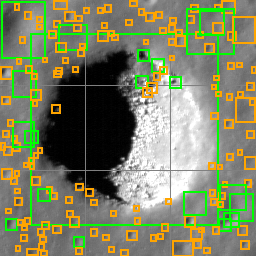

moon_seg_012 {'crater_presence_v1': 'YES', 'crater_center_v1': 'NO', 'crater_largest_location_v1': '1', 'crater_half_count_v1': 'LEFT'}


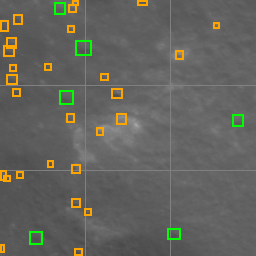

In [27]:
if RUN_SMOKE:
    step('smoke', '--persist', PERSIST, '--run-id', RUN_ID, '--session-id', SESSION_ID)
    from IPython.display import display
    from PIL import Image
    smoke_folder = WORKSPACE/'outputs/IBM-Craters'/(RUN_ID+'_smoke_'+SESSION_ID[:8])
    for path in sorted((smoke_folder/'overlays').glob('*.png')):
        record = json.loads((smoke_folder/'detections'/(path.stem+'.json')).read_text())
        print(path.stem, record['answers'])
        display(Image.open(path))
else:
    print('Smoke disabled; benchmark is gated until a real successful smoke in this session')


## Запуск
### 7. Полный clean-прогон
Поставить RUN_BENCHMARK=True **здесь**, не повторяя parameters.
Одна загрузка IBM, по одному forward на каждый из 100 снимков.
Прогресс сохраняется в Drive после каждого изображения. При обрыве тот же
RUN_ID/ZIP + RESUME=True, setup, новый smoke и эта ячейка: готовые кадры пропускаются.
Результаты пилота сюда не импортируются — full100 имеет новую воспроизводимую идентичность.

In [28]:
RUN_BENCHMARK = True  # True после технически успешного smoke
if RUN_BENCHMARK:
    try:
        step('run', '--persist', PERSIST, '--run-id', RUN_ID, '--session-id', SESSION_ID,
             *(['--resume'] if RESUME else []))
    finally:
        print('Result ZIP (complete or partial):', PERSIST/(RUN_ID+'_results.zip'))
        print('Drive checkpoints:', PERSIST/'runs/IBM-Craters'/RUN_ID)
else:
    print('Set RUN_BENCHMARK=True in this cell after smoke; do not rerun parameters.')


Log: /content/drive/MyDrive/planetary_benchmark/logs/ibm_full100_v2_clean_72871d1a_run.log
{"event": "ibm_loading", "precision": "float32", "quantization": null}
/content/venv_ibm_val14_v1/lib/python3.12/site-packages/terratorch/tasks/object_detection_task.py:85: UserWarning: The Object Detection Task has to be considered experimental. This is less mature than the other tasks and being further improved.
  warnings.warn(
LunarBackbone: loaded modality info (20 modalities: ['aspect', 'aspect_3m', 'dtm', 'dtm_3m', 'metadata', 'nac', 'slope', 'slope_3m', 'static_maps', 'tok_aspect', 'tok_aspect_3m', 'tok_dtm', 'tok_dtm_3m', 'tok_nac', 'tok_slope', 'tok_slope_3m', 'tok_uv', 'tok_vis', 'uv', 'vis'])
encoder_embeddings.aspect.mod_emb
encoder_embeddings.aspect.pos_emb
encoder_embeddings.aspect.proj.weight
encoder_embeddings.aspect_3m.mod_emb
encoder_embeddings.aspect_3m.pos_emb
encoder_embeddings.aspect_3m.proj.weight
encoder_embeddings.dtm.mod_emb
encoder_embeddings.dtm.pos_emb
encoder_embedd

### 8. Результаты и полнота
Проверка 100 снимков / 400 уникальных ответов; отображаем только несколько overlays, не все 100. Это не вычисляет accuracy без эталонов.

{'success': True, 'images': 100, 'answers': 400, 'scientific_score_available': False, 'smoke_means': 'execution passed; visual/head/input/holdout admission remains separate'}
mars_seg_001 test Mirali33/mb-crater_multi_seg {'crater_presence_v1': 'YES', 'crater_center_v1': 'YES', 'crater_largest_location_v1': '3', 'crater_half_count_v1': 'RIGHT'}


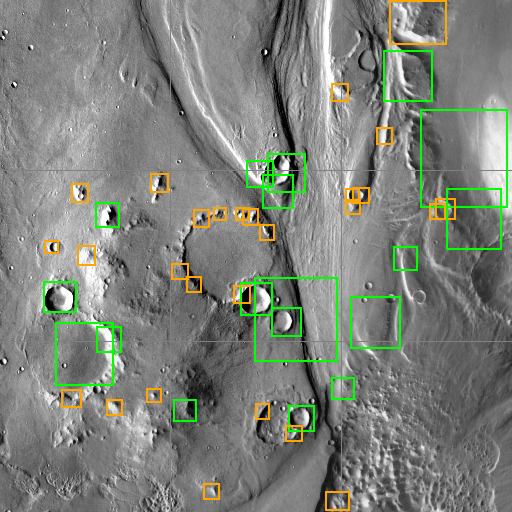

mars_seg_002 test Mirali33/mb-crater_multi_seg {'crater_presence_v1': 'YES', 'crater_center_v1': 'YES', 'crater_largest_location_v1': '7', 'crater_half_count_v1': 'LEFT'}


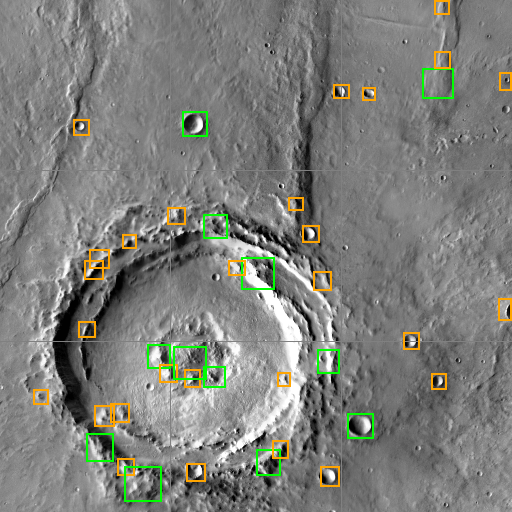

mars_seg_003 test Mirali33/mb-crater_multi_seg {'crater_presence_v1': 'YES', 'crater_center_v1': 'YES', 'crater_largest_location_v1': '2', 'crater_half_count_v1': 'RIGHT'}


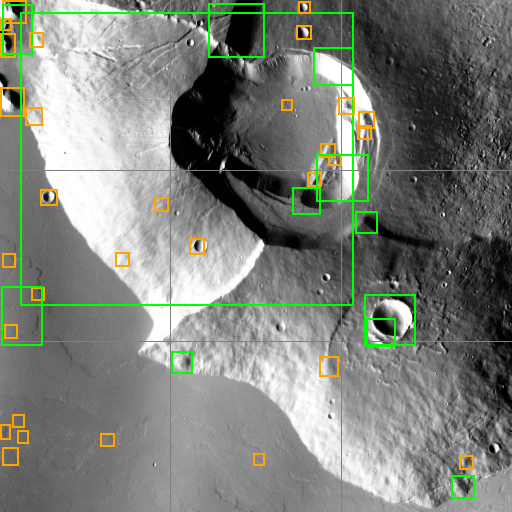

mars_seg_004 test Mirali33/mb-crater_multi_seg {'crater_presence_v1': 'YES', 'crater_center_v1': 'YES', 'crater_largest_location_v1': '7', 'crater_half_count_v1': 'LEFT'}


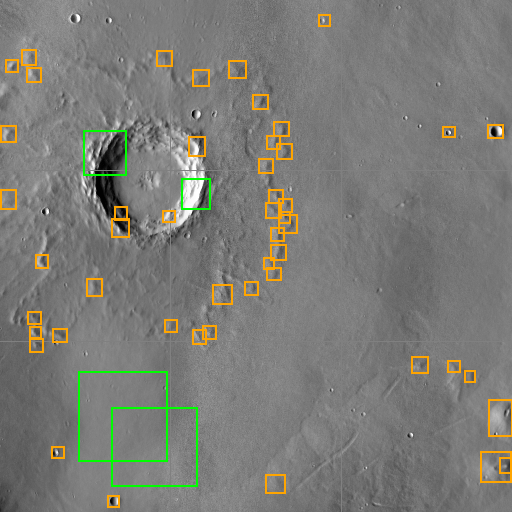

Send: /content/drive/MyDrive/planetary_benchmark/ibm_full100_v2_clean_results.zip


In [29]:
result_folder = WORKSPACE/'outputs/IBM-Craters'/RUN_ID
if (result_folder/'summary.json').is_file():
    summary = json.loads((result_folder/'summary.json').read_text())
    predictions = [json.loads(line) for line in (result_folder/'predictions.jsonl').read_text().splitlines() if line.strip()]
    print(summary)
    assert summary['success'] is True and summary['images'] == 100 and summary['answers'] == 400
    assert len(predictions) == len({row['request_id'] for row in predictions}) == 400
    from IPython.display import display
    from PIL import Image
    for path in sorted((result_folder/'overlays').glob('*.png'))[:4]:
        record = json.loads((result_folder/'detections'/(path.stem+'.json')).read_text())
        print(path.stem, record['source_split'], record['source_dataset'], record['answers'])
        display(Image.open(path))
else:
    print('No completed full run. Keep RUN_ID and ZIP; use logs/checkpoints for resume.')
print('Send:', PERSIST/(RUN_ID+'_results.zip'))


## Следующий шаг
Пришли `ibm_full100_v2_clean_results.zip` из MyDrive/planetary_benchmark.
При сбое — частичный ZIP и соответствующий log. Не менять score threshold,
вопросы или разметку по ошибкам test. Оценка выполняется отдельно локальным
eval-kit, не загружаемым в Colab; кандидатные ответы не являются принятым GT.
Новый full100 notebook проверяется CPU-тестами, но полный GPU-путь ещё не выполнен.